# 01 · Replicate Singh & Bagler (2018) with FlavorAudit

This notebook reproduces two published results on CulinaryDB using only the library:

1. **Fig. 4: food pairing in the 22 world regions.** Each cuisine's mean flavor sharing is compared with a random null that keeps the cuisine's own ingredients and recipe sizes. We check the sign of Z for every region and the rank correlation with the published Z.
2. **Fig. 5: the ingredients that drive the pattern (χ%).** Korea's top contributor should be Soybean Sauce.

**Definitions** (also on the *Methods and definitions* page of the docs). For a recipe $R$ with $n \ge 2$ ingredients, whose flavor-compound sets are $C_i$,

$$N_s(R) = \frac{2}{n(n-1)} \sum_{i<j \in R} |C_i \cap C_j| .$$

The cuisine score $\bar N_s$ is the mean over its recipes, and

$$Z = \sqrt{N_{rand}}\;\frac{\bar N_s^{\,cuisine} - \bar N_s^{\,rand}}{\sigma_{rand}}, \qquad N_{rand} = 100{,}000$$

(Jain, Rakhi & Bagler 2015, eq. 3; Singh & Bagler 2018). Z > 0 means *uniform* food pairing: ingredients that share flavor compounds are used together. Z < 0 means *contrasting* food pairing.

**Run time: under a minute.** Each null here has **20,000 recipes instead of the paper's 100,000**. Z keeps the paper's scale, because $N_{rand}$ = 100,000 stays in the formula (the `n_ref` argument of `food_pairing`). The smaller null only adds Monte-Carlo noise, which is measured below. The full replication (four nulls with 100,000 recipes each) is `analysis/replication/replicate_singh_bagler.py`, reported in `docs/replication_report.md`.

**Data.** The notebook reads three sources from `data/raw`; none of them ships with the package:
- CulinaryDB and FlavorDB (CoSyLab, IIIT-Delhi; CC BY-NC-SA 3.0);
- the Ahn et al. (2011) flavor network (CC BY 4.0).

The published values in `data/reference/singh_bagler_2018_targets.json` were read from the CulinaryDB figures. Their reading error is about ±3 for the random-null Z.

In [1]:
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

import flavoraudit as fa

# The repository root: the first folder upwards whose data/raw holds the source databases.
REPO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data" / "raw" / "culinarydb").is_dir())
TARGETS = json.loads((REPO / "data" / "reference" / "singh_bagler_2018_targets.json").read_text())
CODE = {name: code for code, name in TARGETS["region_codes"].items()}  # "Korea" -> "KOR"
N_NULL, SEED = 20_000, 0

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})
print(f"flavoraudit {fa.__version__}")

flavoraudit 0.1.0.dev0


`load_world` reads the three databases, builds every ingredient's flavor profile and the shared-compound matrix $S_{ij} = |C_i \cap C_j|$, and assembles the 22 real cuisines.

In [2]:
t0 = time.perf_counter()
world = fa.load_world(REPO / "data" / "raw")
n_recipes = sum(len(c) for c in world.cuisines.values())
print(
    f"{len(world.regions)} regions, {n_recipes:,} recipes, S over {world.S.shape[0]:,} CulinaryDB entities "
    f"({time.perf_counter() - t0:.1f} s)"
)

22 regions, 45,542 recipes, S over 1,033 CulinaryDB entities (1.8 s)


## Food pairing of the 22 regions (Fig. 4)

The table lists the regions in the paper's order (by published Z). Its columns:
- `recipes`: our recipe count, next to Table 1 of the paper (`recipes_table1`);
- `ns`: the cuisine's $\bar N_s$;
- `delta_ns`: $\Delta N_s$ against the random null;
- `d`: the standardized effect size $\Delta N_s / \sigma_{rand}$;
- `z`: our Z, next to `z_published`.

Since $Z = \sqrt{N_{rand}} \cdot d$, Z depends on $N_{rand}$ and not on the cuisine's size. That is why `d` and $\Delta N_s$ are reported too.

In [3]:
t0 = time.perf_counter()
published = TARGETS["z_vs_null"]["random"]  # region code -> published Z, largest first
rows = []
for region in world.regions:
    cuisine = world.cuisine(region)
    res = fa.food_pairing(cuisine, world.S, null_model="random", n_null=N_NULL, seed=SEED)
    rows.append(
        {
            "code": CODE[region],
            "region": region,
            "recipes": len(cuisine),
            "recipes_table1": TARGETS["table1_counts"][CODE[region]][0],
            "ns": res.ns_cuisine,
            "delta_ns": res.delta_ns,
            "d": res.d,
            "z": res.z_sb,
            "z_published": published[CODE[region]],
        }
    )
fig4 = pd.DataFrame(rows).set_index("code").loc[list(published)]
fig4["same_sign"] = np.sign(fig4["z"]) == np.sign(fig4["z_published"])
print(f"22 regions against {N_NULL:,}-recipe random nulls in {time.perf_counter() - t0:.0f} s")
fig4.round({"ns": 2, "delta_ns": 2, "d": 3, "z": 1})

22 regions against 20,000-recipe random nulls in 3 s


,region,recipes,recipes_table1,ns,delta_ns,d,z,z_published,same_sign
code,,,,,,,,,
ITA,Italy,7502,7504,50.96,16.24,0.781,246.9,263,True
AFR,Africa,650,651,57.57,17.39,0.856,270.6,262,True
CBN,Caribbean,1103,1103,53.14,15.13,0.720,227.8,250,True
GRC,Greece,934,934,58.38,18.52,0.927,293.2,241,True
ESP,Spain,815,816,53.86,14.92,0.708,223.8,229,True
USA,USA,16106,16118,43.15,12.66,0.620,196.1,198,True
INSC,Indian Subcontinent,4057,4058,56.95,13.81,0.506,160.1,172,True
ME,Middle East,993,993,55.34,13.51,0.644,203.8,160,True
MEX,Mexico,3138,3138,44.50,8.16,0.365,115.6,140,True


In [4]:
rho = stats.spearmanr(fig4["z"], fig4["z_published"])
contrasting = sorted(fig4.index[fig4["z"] < 0])
print(f"Sign agreement with the published Z: {fig4['same_sign'].sum()}/{len(fig4)} regions")
print(f"Contrasting cuisines (Z < 0): {', '.join(contrasting)}")
print(f"Spearman rho with the published Z: {rho.statistic:.3f} (p = {rho.pvalue:.1e})")
print(
    f"Median |Z - Z_published|: {(fig4['z'] - fig4['z_published']).abs().median():.1f}; "
    f"smallest |Z|: {fig4['z'].abs().min():.1f}"
)
assert fig4["same_sign"].all()
assert contrasting == sorted(TARGETS["expected_sign"]["contrasting_negative"])

Sign agreement with the published Z: 22/22 regions
Contrasting cuisines (Z < 0): BRI, DACH, EE, JPN, KOR, SCND
Spearman rho with the published Z: 0.981 (p = 1.1e-15)
Median |Z - Z_published|: 17.6; smallest |Z|: 31.2


**How much noise does the 20,000-recipe null add?** The null's mean is estimated with standard error $\sigma_{rand}/\sqrt{n_{null}}$. Through the formula above, Z therefore moves by about $\sqrt{N_{rand}/n_{null}} = \sqrt{5} \approx 2.2$ units, or 1 unit with the paper's 100,000 recipes. This is comparable to the reading error of the published values and far below the smallest |Z| in the table. Ten seeds for Korea:

In [5]:
korea = world.cuisine("Korea")
zs = np.array([fa.food_pairing(korea, world.S, n_null=N_NULL, seed=s).z_sb for s in range(10)])
print(
    f"Korea, 10 seeds: Z = {zs.mean():.1f} ± {zs.std(ddof=1):.1f} (expected SD about {np.sqrt(100_000 / N_NULL):.1f})"
)

Korea, 10 seeds: Z = -55.9 ± 2.7 (expected SD about 2.2)


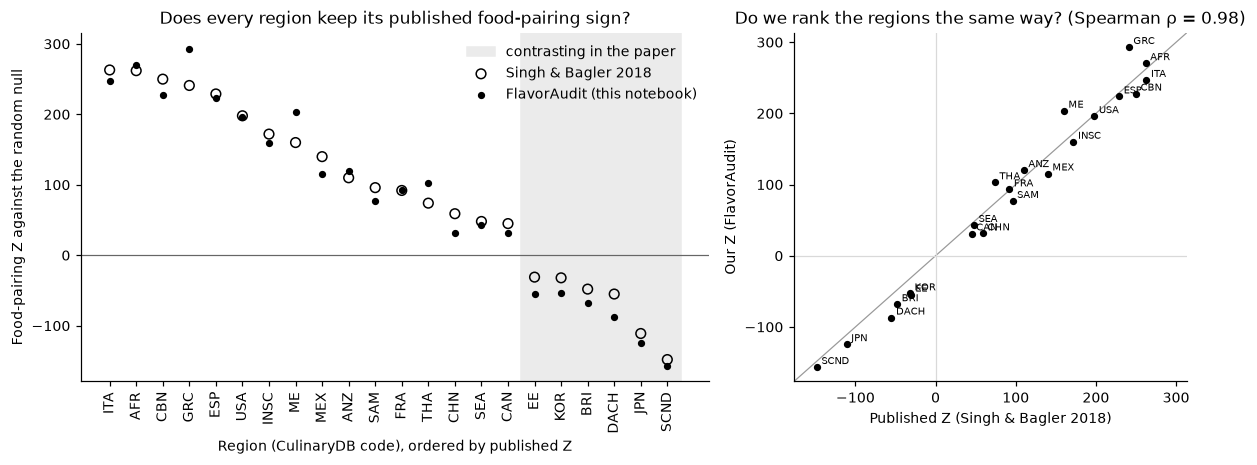

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.3), gridspec_kw={"width_ratios": [1.6, 1]})
x = np.arange(len(fig4))
first_contrasting = int(np.argmax(fig4["z_published"].to_numpy() < 0))  # the paper's last 6 regions
ax1.axvspan(first_contrasting - 0.5, len(fig4) - 0.5, color="0.92", zorder=0, label="contrasting in the paper")
ax1.axhline(0, color="0.4", lw=0.8)
ax1.scatter(x, fig4["z_published"], facecolors="none", edgecolors="black", s=40, label="Singh & Bagler 2018")
ax1.scatter(x, fig4["z"], color="black", s=14, label="FlavorAudit (this notebook)")
ax1.set_xticks(x, fig4.index, rotation=90)
ax1.set_xlabel("Region (CulinaryDB code), ordered by published Z")
ax1.set_ylabel("Food-pairing Z against the random null")
ax1.set_title("Does every region keep its published food-pairing sign?")
ax1.legend(frameon=False, loc="upper right")

lo = fig4[["z", "z_published"]].min().min() - 20
hi = fig4[["z", "z_published"]].max().max() + 20
ax2.plot([lo, hi], [lo, hi], color="0.6", lw=0.8, zorder=0)
ax2.axhline(0, color="0.85", lw=0.8, zorder=0)
ax2.axvline(0, color="0.85", lw=0.8, zorder=0)
ax2.scatter(fig4["z_published"], fig4["z"], color="black", s=14)
for code, row in fig4.iterrows():
    ax2.annotate(code, (row["z_published"], row["z"]), fontsize=6.5, xytext=(3, 2), textcoords="offset points")
ax2.set(xlim=(lo, hi), ylim=(lo, hi), xlabel="Published Z (Singh & Bagler 2018)", ylabel="Our Z (FlavorAudit)")
ax2.set_title(f"Do we rank the regions the same way? (Spearman ρ = {rho.statistic:.2f})")
fig.tight_layout()
plt.show()

## Which ingredients drive the pattern? χ% (Fig. 5)

Singh & Bagler (2018, Sec. IV-C) define an ingredient's contribution as the percentage change in the food-pairing score when the ingredient is removed from the cuisine. `chi_percent` works as follows:
- it removes the ingredient from every recipe and reports the % change in the cuisine's mean $N_s$;
- the change is oriented by the sign of Z, so a positive χ% pushes the cuisine toward its observed pattern (for Korea, contrasting pairing);
- it ranks the 30 most frequent non-additive ingredients.

This calibration reproduces the published contributors best (`docs/replication_report.md`). The function returns rows of $S$, so we map them back to CulinaryDB names.

In [7]:
row_to_entity = {row: entity for entity, row in world.index.items()}  # S row -> CulinaryDB entity id


def ingredient(row: int) -> str:
    return world.profiles.names[row_to_entity[row]]


chi_korea = fa.chi_percent(korea, world.S)
chi_korea.insert(1, "ingredient", chi_korea["row"].map(ingredient))
print("Published top 3 for Korea (χ%):", TARGETS["top3_contribution_percent"]["negative"]["KOR"])
assert chi_korea["ingredient"].iloc[0] == "Soybean Sauce"
chi_korea[["ingredient", "frequency", "ns", "ns_without", "chi_percent"]].head(5).round(3)

Published top 3 for Korea (χ%): {'Soybean Sauce': 16.85, 'Beef': 7.7, 'Vinegar': 6.15}


,ingredient,frequency,ns,ns_without,chi_percent
0,Soybean Sauce,0.601,40.399,45.256,12.021
1,Beef,0.314,40.399,42.227,4.523
2,Vinegar,0.253,40.399,41.782,3.422
3,Cayenne,0.142,40.399,41.569,2.895
4,Egg,0.199,40.399,41.419,2.523


Here `frequency` is the share of Korean recipes that use the ingredient, and `ns_without` is the cuisine's $\bar N_s$ after the ingredient is removed. The same check for every region asks whether the published top contributor is among our top 3:

In [8]:
top3 = TARGETS["top3_contribution_percent"]
published_top3 = {**top3["positive"], **top3["negative"]}  # region code -> {ingredient: published χ%}
rows = []
for region in world.regions:
    ours = [ingredient(r) for r in fa.chi_percent(world.cuisine(region), world.S)["row"].head(3)]
    theirs = list(published_top3[CODE[region]])
    rows.append(
        {
            "code": CODE[region],
            "ours (top 3)": ", ".join(ours),
            "published (top 3)": ", ".join(theirs),
            "published #1 in our top 3": theirs[0] in ours,
            "overlap": len(set(ours) & set(theirs)),
        }
    )
drivers = pd.DataFrame(rows).set_index("code").loc[list(published)]
print(
    f"Published top contributor in our top 3: {drivers['published #1 in our top 3'].sum()}/22 regions; "
    f"top-3 overlap: {drivers['overlap'].sum()}/66 entries"
)
drivers

Published top contributor in our top 3: 22/22 regions; top-3 overlap: 63/66 entries


,ours (top 3),published (top 3),published #1 in our top 3,overlap
code,,,,
ITA,"Olive, Pepper, Tomato","Olive, Pepper, Tomato",True,3
AFR,"Pepper, Olive, Coriander","Pepper, Olive, Coriander",True,3
CBN,"Pepper, Lime, Garlic","Pepper, Lime, Garlic",True,3
GRC,"Olive, Pepper, Tomato","Olive, Pepper, Tomato",True,3
ESP,"Olive, Pepper, Capsicum","Olive, Pepper, Capsicum",True,3
USA,"Pepper, Onion, Olive","Pepper, Onion, Olive",True,3
INSC,"Sunflower, Capsicum, Coriander","Sunflower, Coriander, Capsicum",True,3
ME,"Pepper, Olive, Lemon Juice","Olive, Pepper, Garlic",True,2
MEX,"Tomato, Onion, Coriander","Tomato, Onion, Coriander",True,3


## Summary

- The printed checks above are recomputed from the data every time the notebook runs; the `assert` lines stop the notebook if a sign or Korea's top contributor ever changes.
- Some differences from the paper remain. Our Korea, for example, comes out more strongly contrasting than published, and χ% magnitudes differ while the rankings hold. These differences are expected, because the 2018 FlavorDB snapshot used in the paper is no longer online and today's FlavorDB has updated molecule lists (`docs/replication_report.md`).
- Everything here reproduces published methods (Ahn et al. 2011; Jain, Rakhi & Bagler 2015; Singh & Bagler 2018) and is not a new result. It is the gate the project had to pass before analysing any LLM recipe.

Next: `02_audit_recipes.ipynb` scores a collection of recipes against a real cuisine.